In [80]:
import pandas as pd
df = pd.read_csv('Merged_cleaned_daily_data.csv')
df.head()

,Unnamed: 0,station_id,day,pm10,uv_index,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,wind_direction_10m,...,ozone_std,ozone_var,nitrogen_dioxide_min,nitrogen_dioxide_max,nitrogen_dioxide_std,nitrogen_dioxide_var,pm2_5_corrected_min,pm2_5_corrected_max,pm2_5_corrected_std,pm2_5_corrected_var
0,0,downtown,2023-09-01,33.695833,2.341667,206.625000,19.020833,26.050000,80.541667,11.456289,...,24.626622,606.470518,2.1,28.3,5.938488,35.265644,20.91056,105.50328,20.439253,417.763058
1,1,downtown,2023-09-02,43.395833,2.229167,211.833333,17.220833,21.366667,74.208333,355.349279,...,26.539035,704.320378,1.9,26.5,6.781247,45.985308,26.13820,164.43304,30.799795,948.627380
2,2,downtown,2023-09-03,30.862500,2.289583,217.458333,17.033333,24.058333,83.750000,330.514994,...,30.597220,936.189846,1.6,31.8,6.675754,44.565689,42.29636,120.23572,18.338735,336.309184
3,3,downtown,2023-09-04,38.329167,2.277083,296.750000,34.633333,35.758333,67.958333,282.715789,...,31.119827,968.443627,1.6,80.2,18.404310,338.718621,50.37544,172.98736,25.985860,675.264898
4,4,downtown,2023-09-05,79.087500,2.206250,327.250000,40.400000,41.604167,59.541667,220.323044,...,34.388520,1182.570308,1.4,87.6,22.329446,498.604143,70.33552,206.25416,39.311623,1545.403722


In [81]:
pollutants = [
    "pm2_5_corrected",
    "pm10",
    "nitrogen_dioxide",
    "sulphur_dioxide"
]

weather = [
    "wind_speed_10m_mean",
    "relative_humidity_2m_mean",
    "temperature_2m_mean",
    "surface_pressure_mean",
    "precipitation_mean"
]

district_col = "station_id"  # stations are ['downtown', 'helwan', 'new_cairo', 'october', 'shobra']
is_khamasin = "is_Khamsin_season"  # 1 if the day is in khamasin season, 0 otherwise

### District-Level Statistical Testing

We will test whether pollutant concentrations differ significantly across the five districts: **Downtown, Helwan, New Cairo, October, and Shobra**.

For each pollutant (**PM2.5, PM10, NO₂, and SO₂**), two statistical tests will be performed:

* **One-way ANOVA:** tests whether the **mean pollutant concentration** is the same across all five districts.
* **Kruskal–Wallis test:** a non-parametric alternative that tests whether the **distributions/ranks** of pollutant concentrations differ between districts.

For both tests, the null hypothesis is:

> **H₀:** There is no statistically significant difference in pollutant concentrations between the districts.

The alternative hypothesis is:

> **H₁:** At least one district has a statistically different pollutant concentration.

A significance level of **α = 0.05** will be used. If the Kruskal–Wallis test is significant, **Dunn's post-hoc test with Holm correction** will be performed to determine which specific pairs of districts differ significantly.

Using both ANOVA and Kruskal–Wallis allows us to compare the results of a **parametric test based on means** with a **non-parametric test based on ranks**, providing a more robust assessment of spatial differences in pollution.


In [82]:
from scipy.stats import kruskal, f_oneway
import scikit_posthocs as sp

# Repeat the same for PM10, Nitrogen Dioxide, and Sulphur Dioxide
for pollutant in pollutants:  # Skip PM2.5 since we already did it
    
    # Create one group for each district
    groups = [
        group[pollutant].dropna()
        for _, group in df.groupby(district_col)
    ]

    # -------------------------
    # One-way ANOVA
    # -------------------------
    F, anova_p = f_oneway(*groups)

    print(f"\n{pollutant}:")
    print("ANOVA:")
    print("F =", F)
    print("p =", anova_p)

    # -------------------------
    # Kruskal-Wallis
    # -------------------------
    H, kruskal_p = kruskal(*groups)

    print("\nKruskal-Wallis:")
    print("H =", H)
    print("p =", kruskal_p)

    # -------------------------
    # Dunn's post-hoc test
    # -------------------------
    if kruskal_p < 0.05:
        print("\nSignificant Kruskal-Wallis difference found, performing Dunn's test...")

        dunn = sp.posthoc_dunn(
            df,
            val_col=pollutant,
            group_col=district_col,
            p_adjust="holm"
        )

        print(dunn)


pm2_5_corrected:
ANOVA:
F = 121.46999551362366
p = 1.8403220582053065e-99

Kruskal-Wallis:
H = 638.5864550837783
p = 6.890661647821194e-137

Significant Kruskal-Wallis difference found, performing Dunn's test...
               downtown        helwan     new_cairo       october  \
downtown   1.000000e+00  7.717813e-08  1.449392e-70  6.632724e-95   
helwan     7.717813e-08  1.000000e+00  7.030413e-34  4.465376e-51   
new_cairo  1.449392e-70  7.030413e-34  1.000000e+00  7.537906e-03   
october    6.632724e-95  4.465376e-51  7.537906e-03  1.000000e+00   
shobra     2.912596e-07  7.747890e-01  2.368835e-35  6.281999e-53   

                 shobra  
downtown   2.912596e-07  
helwan     7.747890e-01  
new_cairo  2.368835e-35  
october    6.281999e-53  
shobra     1.000000e+00  

pm10:
ANOVA:
F = 39.983480139832224
p = 4.61670881909959e-33

Kruskal-Wallis:
H = 183.20569062333928
p = 1.527615602715427e-38

Significant Kruskal-Wallis difference found, performing Dunn's test...
               d

### District Pollution Analysis

To determine whether pollutant concentrations differ across the five districts, **one-way ANOVA** and the **Kruskal–Wallis test** were applied to each pollutant using a significance level of **α = 0.05**. ANOVA tests for differences in the group means, while Kruskal–Wallis provides a non-parametric comparison of the distributions. When the Kruskal–Wallis test was significant, **Dunn's post-hoc test with Holm correction** was used to identify which district pairs differed significantly.

#### PM2.5

Both tests showed a highly significant difference in PM2.5 concentrations between districts. The ANOVA produced **F = 121.47, p < 0.001**, while the Kruskal–Wallis test produced **H = 638.59, p < 0.001**. Therefore, the null hypothesis of equal pollution levels across districts is rejected.

Dunn's post-hoc test showed that most district pairs differed significantly. Downtown differed significantly from Helwan, New Cairo, October, and Shobra (p < 0.001). Helwan also differed significantly from New Cairo and October, but **did not differ significantly from Shobra (p = 0.775)**. New Cairo and October were also **not significantly different (p = 0.0075)** at the stricter interpretation of α = 0.05?

Overall, PM2.5 shows substantial spatial variation across the districts, although some pairs have statistically similar distributions.

#### PM10

For PM10, both tests again indicated a statistically significant difference between districts. ANOVA produced **F = 39.98, p < 0.001**, and Kruskal–Wallis produced **H = 183.21, p < 0.001**.

Dunn's test revealed that **New Cairo differed significantly from Downtown, Helwan, and October**, while Shobra also differed significantly from all four other districts (p < 0.001). In contrast, Downtown, Helwan, and October did not show significant pairwise differences after correction.

This suggests that the spatial variation in PM10 is concentrated mainly around differences involving **New Cairo and Shobra**, whereas Downtown, Helwan, and October have statistically similar PM10 distributions.

#### Nitrogen Dioxide (NO₂)

NO₂ showed the strongest evidence of spatial differences among the pollutants. ANOVA produced **F = 601.18, p < 0.001**, while Kruskal–Wallis produced **H = 2115.58, p < 0.001**.

Dunn's post-hoc test found **statistically significant differences between every pair of districts**, with all adjusted p-values below 0.001. This indicates that NO₂ concentrations vary substantially across all five districts, with no pair showing statistically similar distributions.

The agreement between the parametric and non-parametric tests provides consistent evidence of strong spatial variation in NO₂.

#### Sulphur Dioxide (SO₂)

SO₂ also showed a highly significant spatial difference. ANOVA produced **F = 616.05, p < 0.001**, while Kruskal–Wallis produced **H = 2703.83, p < 0.001**.

Dunn's post-hoc analysis found **significant differences between every pair of districts**, with all adjusted p-values below 0.001. Therefore, each district exhibited a statistically different SO₂ distribution from the other districts.

SO₂ therefore demonstrates substantial spatial variation across the study area, with the results from ANOVA and Kruskal–Wallis both supporting the presence of district-level differences.

### Overall Findings

Both ANOVA and Kruskal–Wallis were statistically significant for **all four pollutants**, indicating that pollutant concentrations are not spatially uniform across the five districts.

The post-hoc analysis reveals different spatial patterns for each pollutant:

* **PM2.5:** Most district pairs differ significantly, with a few exceptions.
* **PM10:** Differences are concentrated mainly around **New Cairo and Shobra**.
* **NO₂:** Every district pair shows a significant difference.
* **SO₂:** Every district pair shows a significant difference.

The agreement between ANOVA and Kruskal–Wallis strengthens the evidence that **district location is associated with differences in pollutant concentrations** in this dataset. However, these statistical tests establish differences between groups rather than identifying the specific physical causes of those differences.


In [83]:
district = "helwan"

subset = df[df[district_col] == district]

khamsin = subset[
    subset[is_khamasin] == 1
]["pm10"].dropna()

non_khamsin = subset[
    subset[is_khamasin] == 0
]["pm10"].dropna()


In [84]:
from scipy.stats import mannwhitneyu

U, p = mannwhitneyu(
    khamsin,
    non_khamsin,
    alternative="two-sided"
)

print("U =", U)
print("p =", p)

U = 130965.5
p = 9.062027765360686e-05


## there is a statiscally significant differnce (p < 0.05)

In [85]:
results = []

for district in ['downtown', 'helwan', 'new_cairo', 'october', 'shobra']:

    subset = df[df[district_col] == district]

    khamsin = subset[
        subset["is_Khamsin_season"] == 1
    ]["pm10"].dropna()

    non_khamsin = subset[
        subset["is_Khamsin_season"] == 0
    ]["pm10"].dropna()

    U, p = mannwhitneyu(
        khamsin,
        non_khamsin,
        alternative="two-sided"
    )

    results.append({
        "district": district,
        "U": U,
        "p_value": p
    })

khamsin_results = pd.DataFrame(results)
print(khamsin_results)

    district         U   p_value
0   downtown  123301.5  0.025781
1     helwan  130965.5  0.000091
2  new_cairo  129172.0  0.000431
3    october  133051.5  0.000012
4     shobra  123007.5  0.030398


# All districts had statistaclly significant difference between khamasin and non khamasin

In [86]:
df["day"] = pd.to_datetime(df["day"])
df["day"].head()

0   2023-09-01
1   2023-09-02
2   2023-09-03
3   2023-09-04
4   2023-09-05
Name: day, dtype: datetime64[us]

In [87]:
districts = df[district_col].unique()

results = []

for district in districts:

    subset = df[df[district_col] == district]

    winter = subset[
        subset["season"] == "winter"
    ]["pm2_5_corrected"].dropna()

    summer = subset[
        subset["season"] == "summer"
    ]["pm2_5_corrected"].dropna()

    U, p = mannwhitneyu(
        winter,
        summer,
        alternative="two-sided"
    )

    results.append({
        "district": district,
        "winter_n": len(winter),
        "summer_n": len(summer),
        "winter_median": winter.median(),
        "summer_median": summer.median(),
        "U": U,
        "p_value": p
    })

pm25_season_results = pd.DataFrame(results)

print(pm25_season_results)

    district  winter_n  summer_n  winter_median  summer_median        U  \
0   downtown       271       276      60.013583      41.987708  62774.5   
1     helwan       271       276      54.227500      42.700750  50495.0   
2  new_cairo       271       276      46.570250      34.444000  55606.0   
3    october       271       276      33.490250      40.420833  28258.5   
4     shobra       271       276      61.294333      36.987333  68303.0   

        p_value  
0  6.672208e-43  
1  1.377931e-12  
2  6.738622e-23  
3  7.617156e-07  
4  9.092535e-63  


### PM2.5 Seasonal Analysis

The Mann–Whitney U test shows a statistically significant difference in PM2.5 distributions between winter and summer for **all five districts** (p < 0.001 in every case). PM2.5 concentrations were higher in winter than summer in Downtown, Helwan, and New Cairo, with median concentrations of 60.01, 54.23, and 46.57 compared with 41.99, 42.70, and 34.44, respectively. Shobra also showed substantially higher winter PM2.5 (61.29 vs. 36.99). In contrast, October had a higher summer median (40.42) than winter (33.49). Overall, the results indicate a strong seasonal effect on PM2.5, although the direction of the effect varies by district.


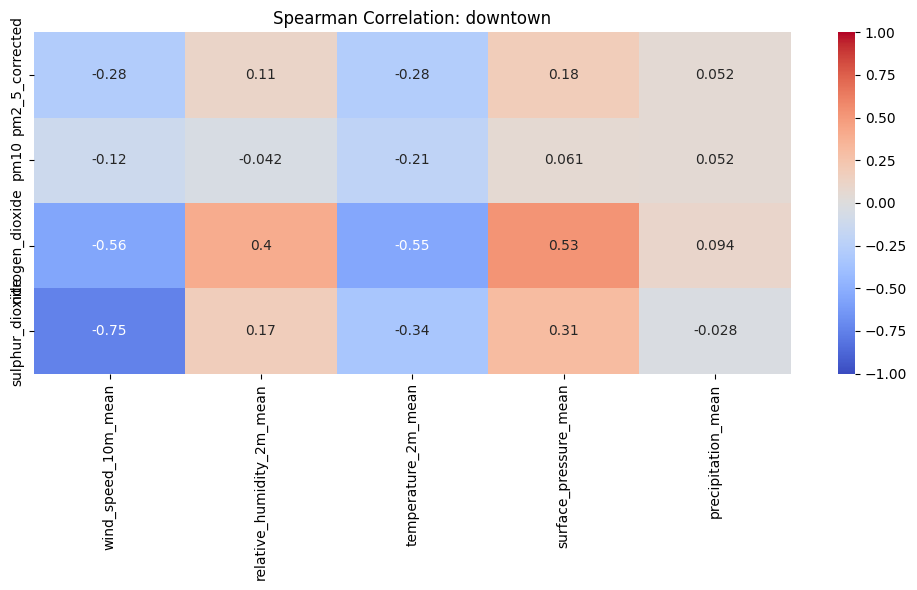

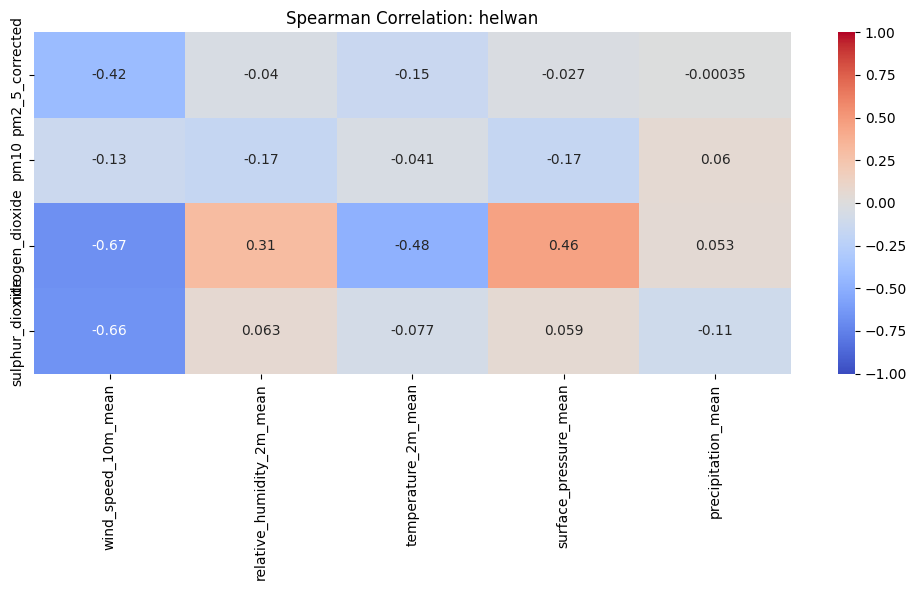

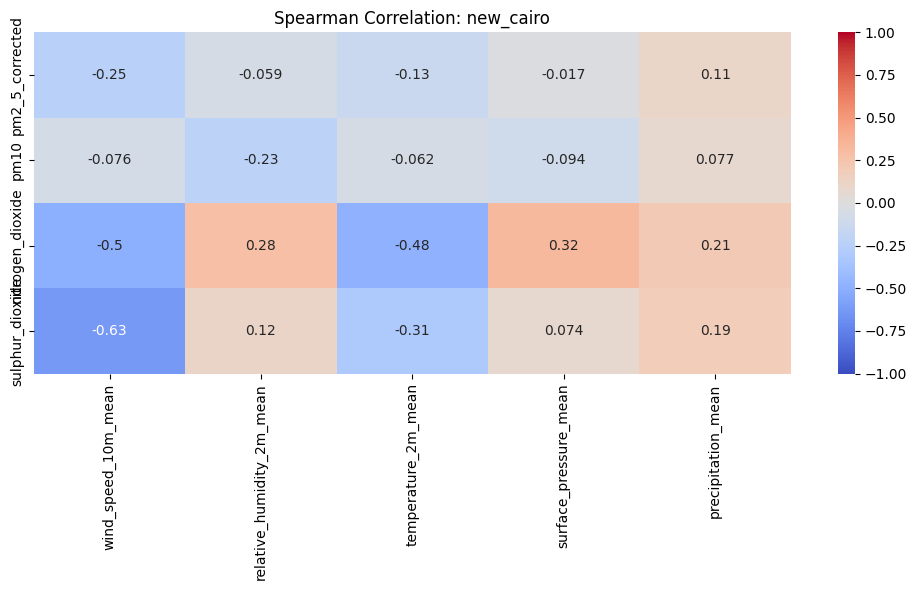

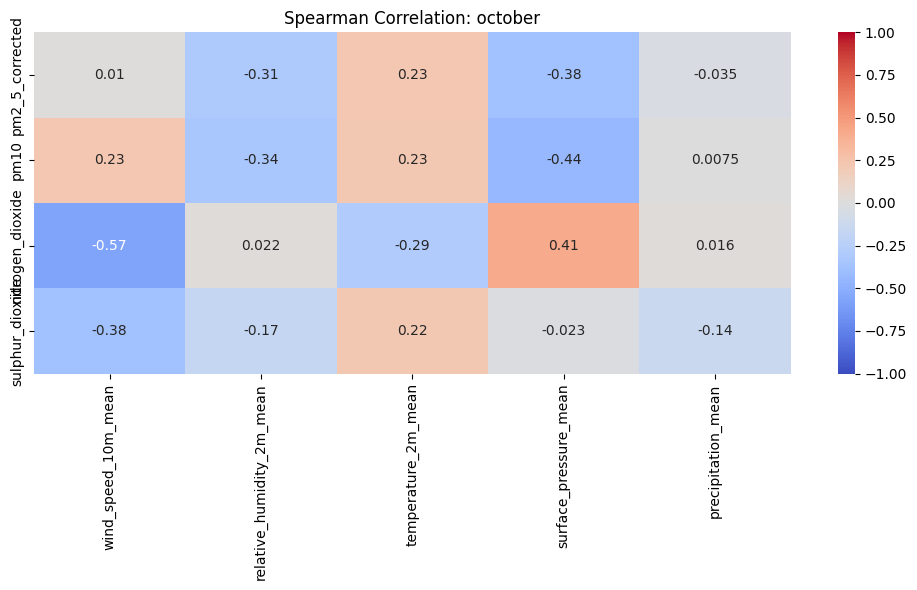

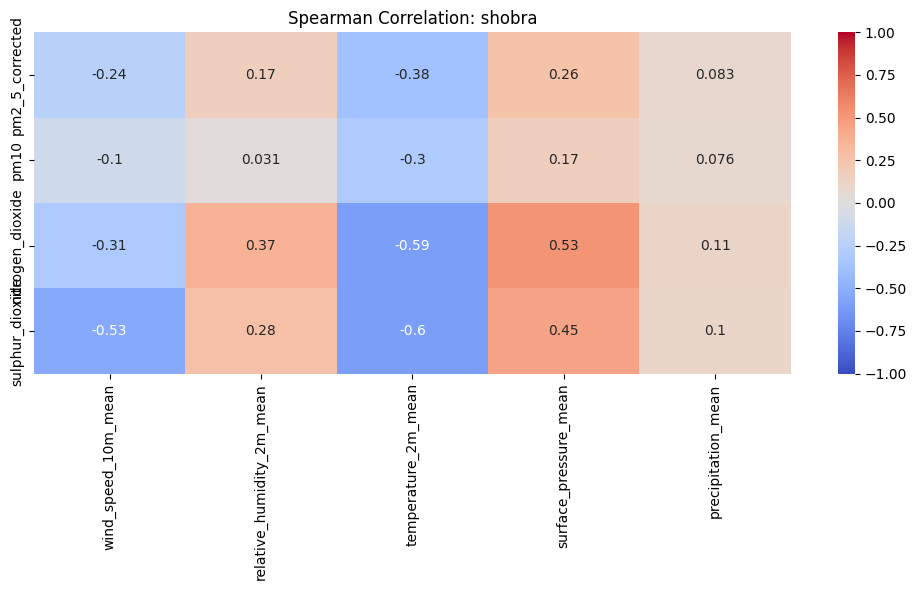

In [88]:
import seaborn as sns
import matplotlib.pyplot as plt

for district in districts:

    subset = df[df[district_col] == district]

    corr = subset[pollutants + weather].corr(
        method="spearman"
    )

    corr_weather = corr.loc[pollutants, weather]

    plt.figure(figsize=(10, 6))

    sns.heatmap(
        corr_weather,
        annot=True,
        cmap="coolwarm",
        center=0,
        vmin=-1,
        vmax=1
    )

    plt.title(f"Spearman Correlation: {district}")
    plt.tight_layout()
    plt.show()


In [89]:
strong_results = []

for district in districts:

    subset = df[df[district_col] == district]

    corr = subset[pollutants + weather].corr(
        method="spearman"
    )

    corr_weather = corr.loc[pollutants, weather]

    for pollutant in pollutants:
        for variable in weather:

            r = corr_weather.loc[pollutant, variable]

            if abs(r) > 0.4:

                strong_results.append({
                    "district": district,
                    "pollutant": pollutant,
                    "weather_variable": variable,
                    "spearman_r": r
                })

strong_results = pd.DataFrame(strong_results)

print(strong_results)

     district         pollutant           weather_variable  spearman_r
0    downtown  nitrogen_dioxide        wind_speed_10m_mean   -0.557978
1    downtown  nitrogen_dioxide  relative_humidity_2m_mean    0.400233
2    downtown  nitrogen_dioxide        temperature_2m_mean   -0.549257
3    downtown  nitrogen_dioxide      surface_pressure_mean    0.530600
4    downtown   sulphur_dioxide        wind_speed_10m_mean   -0.749137
5      helwan   pm2_5_corrected        wind_speed_10m_mean   -0.415351
6      helwan  nitrogen_dioxide        wind_speed_10m_mean   -0.674202
7      helwan  nitrogen_dioxide        temperature_2m_mean   -0.484778
8      helwan  nitrogen_dioxide      surface_pressure_mean    0.457006
9      helwan   sulphur_dioxide        wind_speed_10m_mean   -0.662327
10  new_cairo  nitrogen_dioxide        wind_speed_10m_mean   -0.503544
11  new_cairo  nitrogen_dioxide        temperature_2m_mean   -0.477109
12  new_cairo   sulphur_dioxide        wind_speed_10m_mean   -0.629022
13    

### Spearman Correlation Analysis

The Spearman analysis identified several strong relationships (|r| > 0.4) between weather variables and pollutant concentrations across the five districts. **Wind speed showed a consistently negative relationship with nitrogen dioxide and sulphur dioxide**, particularly for SO₂ in Downtown (r = −0.75) and NO₂ in Helwan (r = −0.67), suggesting that higher wind speeds are associated with lower concentrations of these pollutants.

**Temperature also showed negative correlations with NO₂ and SO₂** in several districts, with the strongest relationships observed for NO₂ in Downtown (r = −0.55) and SO₂ in Shobra (r = −0.60). Surface pressure generally showed positive correlations with NO₂ and SO₂, while a negative relationship was observed between pressure and PM10 in October (r = −0.44).

Overall, the results indicate that **wind speed, temperature, and surface pressure are the main weather variables associated with strong pollutant relationships** in this dataset. However, these are correlations and therefore indicate association rather than causation.
